Loading model...
Model: dzinampini/beans-leaf-disease-detection


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]


Model loaded successfully!
Device: cpu

Disease classes available in the model:
0 : angular_leaf_spot
1 : bean_rust
2 : healthy

UPLOAD A BEAN LEAF IMAGE


Saving bean angular1.jpg to bean angular1.jpg


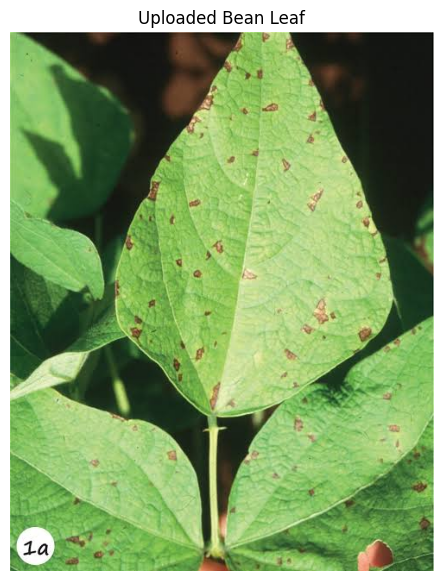



          PREDICTION RESULT
Image       : bean angular1.jpg
Prediction  : angular_leaf_spot
Confidence  : 99.67%

Top predictions:
------------------------------------------
angular_leaf_spot: 99.67%
bean_rust: 0.18%
healthy: 0.14%
------------------------------------------


In [3]:
# ============================================================
# BEANS LEAF DISEASE DETECTION - HUGGING FACE
# Model: dzinampini/beans-leaf-disease-detection
# Google Colab - Single Cell
# ============================================================

# 1. Install required libraries
!pip -q install -U transformers accelerate huggingface_hub safetensors

# 2. Import libraries
import torch
from PIL import Image
from transformers import AutoImageProcessor, AutoModelForImageClassification
from google.colab import files
import matplotlib.pyplot as plt

# ============================================================
# 3. MODEL
# ============================================================

MODEL_NAME = "dzinampini/beans-leaf-disease-detection"

print("Loading model...")
print("Model:", MODEL_NAME)

try:
    processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
    model = AutoModelForImageClassification.from_pretrained(MODEL_NAME)

    # Use GPU if available
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    model.eval()

    print("\nModel loaded successfully!")
    print("Device:", device)

except Exception as e:
    print("\nERROR WHILE LOADING MODEL")
    print("--------------------------------")
    print(e)
    print("\nThe Hugging Face repository may be private, unavailable,")
    print("or may use an architecture that requires different code.")

# ============================================================
# 4. SHOW MODEL CLASSES
# ============================================================

print("\nDisease classes available in the model:")

try:
    id2label = model.config.id2label

    for class_id, label in id2label.items():
        print(class_id, ":", label)

except Exception as e:
    print("Could not read class labels:", e)

# ============================================================
# 5. UPLOAD LEAF IMAGE
# ============================================================

print("\n==========================================")
print("UPLOAD A BEAN LEAF IMAGE")
print("==========================================")

uploaded = files.upload()

if len(uploaded) == 0:
    print("No image uploaded.")

else:

    image_name = list(uploaded.keys())[0]

    # Open image
    image = Image.open(image_name).convert("RGB")

    # Display image
    plt.figure(figsize=(7, 7))
    plt.imshow(image)
    plt.axis("off")
    plt.title("Uploaded Bean Leaf")
    plt.show()

    # ========================================================
    # 6. PREPROCESS IMAGE
    # ========================================================

    inputs = processor(images=image, return_tensors="pt")

    # Move input to same device as model
    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    # ========================================================
    # 7. PREDICTION
    # ========================================================

    with torch.no_grad():
        outputs = model(**inputs)

    # Convert logits to probabilities
    probabilities = torch.softmax(outputs.logits, dim=-1)[0]

    # Get highest probability
    predicted_class_id = torch.argmax(probabilities).item()
    confidence = probabilities[predicted_class_id].item()

    predicted_label = model.config.id2label[predicted_class_id]

    # ========================================================
    # 8. DISPLAY RESULT
    # ========================================================

    print("\n")
    print("==========================================")
    print("          PREDICTION RESULT")
    print("==========================================")

    print("Image       :", image_name)
    print("Prediction  :", predicted_label)
    print("Confidence  :", f"{confidence * 100:.2f}%")

    print("==========================================")

    # ========================================================
    # 9. TOP 3 PREDICTIONS
    # ========================================================

    top_k = min(3, len(probabilities))

    top_probabilities, top_indices = torch.topk(
        probabilities,
        top_k
    )

    print("\nTop predictions:")
    print("------------------------------------------")

    for probability, class_id in zip(
        top_probabilities,
        top_indices
    ):

        class_id = class_id.item()
        probability = probability.item()

        label = model.config.id2label[class_id]

        print(
            f"{label}: {probability * 100:.2f}%"
        )

    print("------------------------------------------")